In [2]:
!pip install wfdb

import json
import numpy as np
import wfdb

params = {
    "kayitlar": ["100", "101", "103", "115", "122", "123", "234"],
    "fs": 360,
    "k_esik": 3,
    "distance": 90,
    "tolerans": 54,
    "f1_esik": 0.95,
    "SNR": list(range(30, -31, -2)),
    "Y": {"tur": "yuksek_geciren", "frekans_hz": 0.5, "derece": 2},
    "A": {"tur": "alcak_geciren", "frekans_hz": 40, "derece": 4},
    "Ç": {"tur": "centik", "frekans_hz": 60, "Q": 30}
}

with open("params.json", "w", encoding="utf-8") as dosya:
    json.dump(params, dosya, ensure_ascii=False, indent=2)

kayitlar = params["kayitlar"]
atim_sembolleri = set("N L R B A a J S V r F e j n E / f Q".split())
# Buradaki "R", sağ dal bloğu atımının anotasyon sembolüdür.

x = {}
ref = {}
gurultu = {}
kanal_adlari = {}
ornekleme_hizlari = {}

for kayit in kayitlar:
    rec = wfdb.rdrecord(kayit, pn_dir="mitdb", channels=[0])
    x[kayit] = rec.p_signal[:, 0]
    kanal_adlari[kayit] = rec.sig_name[0]
    ornekleme_hizlari[kayit] = rec.fs

    ann = wfdb.rdann(kayit, "atr", pn_dir="mitdb")
    maske = np.array([sembol in atim_sembolleri for sembol in ann.symbol])
    ref[kayit] = ann.sample[maske]

    print(
        f"{kayit}: fs={rec.fs} Hz | kanal={rec.sig_name[0]} | "
        f"örnek={len(x[kayit])} | ref atım={len(ref[kayit])}"
    )
    assert rec.fs == params["fs"], f"{kayit}: fs beklenen değerle uyuşmuyor."

for ad in ["bw", "ma"]:
    rec = wfdb.rdrecord(ad, pn_dir="nstdb", channels=[0])
    gurultu[ad] = rec.p_signal[:, 0]
    kanal_adlari[ad] = rec.sig_name[0]
    ornekleme_hizlari[ad] = rec.fs

    print(
        f"{ad}: fs={rec.fs} Hz | kanal={rec.sig_name[0]} | "
        f"örnek={len(gurultu[ad])}"
    )
    assert rec.fs == params["fs"], f"{ad}: fs beklenen değerle uyuşmuyor."

# Sonraki hücreler veriyi yeniden okumadan x, ref ve gurultu'yu kullanacak.

100: fs=360 Hz | kanal=MLII | örnek=650000 | ref atım=2273
101: fs=360 Hz | kanal=MLII | örnek=650000 | ref atım=1865
103: fs=360 Hz | kanal=MLII | örnek=650000 | ref atım=2084
115: fs=360 Hz | kanal=MLII | örnek=650000 | ref atım=1953
122: fs=360 Hz | kanal=MLII | örnek=650000 | ref atım=2476
123: fs=360 Hz | kanal=MLII | örnek=650000 | ref atım=1518
234: fs=360 Hz | kanal=MLII | örnek=650000 | ref atım=2753
bw: fs=360 Hz | kanal=noise1 | örnek=650000
ma: fs=360 Hz | kanal=noise1 | örnek=650000


In [3]:
from scipy.signal import find_peaks  # Genlik eşiğini geçen tepeleri bulmak için.

def r_tespit(sinyal):  # Önceki deneyde kullandığımız dedektörü tanımla.
    esik = np.mean(sinyal) + params["k_esik"] * np.std(sinyal)  # Eşiği bu sinyalden hesapla.
    tepeler, _ = find_peaks(
        sinyal,  # İncelenecek sinyal.
        height=esik,  # Tepe yüksekliği en az eşik kadar olsun.
        distance=params["distance"]  # Tepeler arasında en az 90 örnek olsun.
    )
    return tepeler  # Bulunan tepelerin örnek konumlarını döndür.

def f1_hesapla(tepeler, referans):  # Tespitleri referans atımlarla karşılaştır.
    i, j, tp = 0, 0, 0  # İki listenin başlangıç konumlarını ve doğru sayısını belirle.
    tol = params["tolerans"]  # Eşleştirme toleransını sabitlerden al.
    while i < len(tepeler) and j < len(referans):  # Her iki listede atım kaldıkça devam et.
        fark = int(tepeler[i]) - int(referans[j])  # Tespit ve referans arasındaki farkı hesapla.
        if fark < -tol:  # Tespit referanstan fazla erkense:
            i += 1  # Sonraki tespite geç.
        elif fark > tol:  # Tespit referanstan fazla geçse:
            j += 1  # Sonraki referansa geç.
        else:  # Fark ±54 örnek içindeyse:
            tp += 1  # Bir doğru tespit say.
            i += 1  # Bu tespiti tekrar kullanma.
            j += 1  # Bu referansı tekrar kullanma.
    fp = len(tepeler) - tp  # Eşleşmeyen tespitleri say.
    fn = len(referans) - tp  # Bulunamayan referansları say.
    payda = 2 * tp + fp + fn  # F1 paydasını hesapla.
    return 2 * tp / payda if payda > 0 else np.nan  # F1 değerini döndür.

def kirilma(sonuclar, yontem):  # Sonuçların yüksekten düşüğe SNR sırasıyla verilmesini bekle.
    for sira, satir in enumerate(sonuclar):  # Sonuçları sırayla incele.
        if satir[yontem] < params["f1_esik"]:  # İlk kez F1, 0.95'in altına düştüyse:
            if sira == 0:  # İlk SNR düzeyinde bile eşik sağlanmıyorsa:
                return ">+30"  # Önceki deneyle aynı tarama dışı etiketini kullan.
            return satir["SNR"]  # İlk başarısız SNR düzeyini döndür.
    return "<-30"  # Taramada kırılma görülmediyse aynı tarama dışı etiketini kullan.

baseline_tepeler = r_tespit(x["100"])  # 100 kaydında ek gürültüsüz ve filtresiz tespit yap.
baseline_f1 = f1_hesapla(baseline_tepeler, ref["100"])  # Referanslarla F1 hesapla.
print(f"100 | ek gürültü yok | filtre yok | baseline F1 = {baseline_f1:.6f}")  # Sonucu yazdır.

100 | ek gürültü yok | filtre yok | baseline F1 = 0.999560


In [4]:
temiz_f1 = {}  # Her kaydın ek gürültüsüz, filtresiz F1 değerini sakla.

print("Kayıt | Ek gürültüsüz F1 | Eşik kontrolü")  # Tablo başlığını yaz.

for kayit in params["kayitlar"]:  # Seçtiğimiz yedi kaydı sırayla işle.
    tepeler = r_tespit(x[kayit])  # Bellekteki EKG'de aynı dedektörle tepeleri bul.
    skor = f1_hesapla(tepeler, ref[kayit])  # O kaydın referanslarına göre F1 hesapla.
    temiz_f1[kayit] = skor  # Sonucu sonraki değerlendirmeler için sakla.
    durum = "Eşik sağlandı" if skor >= params["f1_esik"] else "Eşik altında"  # 0.95 ile karşılaştır.
    print(f"{kayit:>5} | {skor:.6f}          | {durum}")  # Kaydın sonucunu göster.

Kayıt | Ek gürültüsüz F1 | Eşik kontrolü
  100 | 0.999560          | Eşik sağlandı
  101 | 0.995456          | Eşik sağlandı
  103 | 0.996883          | Eşik sağlandı
  115 | 0.997183          | Eşik sağlandı
  122 | 0.999394          | Eşik sağlandı
  123 | 0.999342          | Eşik sağlandı
  234 | 0.993252          | Eşik sağlandı


In [5]:
from scipy.signal import butter, iirnotch, tf2sos, sosfiltfilt  # Filtre tasarımı ve uygulaması.
import pandas as pd  # Sonuç tablosunu oluşturmak için.

fs = params["fs"]  # Önceden belirlenen örnekleme hızını al.

filtreler = {
    "Y": butter(params["Y"]["derece"], params["Y"]["frekans_hz"],
                btype="highpass", fs=fs, output="sos"),  # 0,5 Hz, 2. derece yüksek geçiren.
    "A": butter(params["A"]["derece"], params["A"]["frekans_hz"],
                btype="lowpass", fs=fs, output="sos")  # 40 Hz, 4. derece alçak geçiren.
}

b, a = iirnotch(params["Ç"]["frekans_hz"], params["Ç"]["Q"], fs=fs)  # 60 Hz, Q=30 çentik tasarla.
filtreler["Ç"] = tf2sos(b, a)  # Çentiği diğer filtrelerle aynı gösterime dönüştür.

tum_sonuclar = {}  # Her kayıt ve gürültü için tüm SNR sonuçlarını sakla.
ozet_satirlari = []  # Kırılma tablosunun satırlarını sakla.

for kayit in params["kayitlar"]:  # Yedi EKG kaydını sırayla işle.
    temiz = x[kayit]  # Bellekteki EKG'yi al.
    ekg_gucu = np.var(temiz)  # Önceki deneyle aynı güç tanımını kullan.

    for gurultu_adi in ["bw", "ma"]:  # İki gürültü türünü ayrı ayrı dene.
        assert len(gurultu[gurultu_adi]) >= len(temiz), "Gürültü kaydı kısa."  # Uzunluğu kontrol et.
        n = gurultu[gurultu_adi][:len(temiz)].copy()  # Gürültünün başlangıç kesitini al.
        n = n - np.mean(n)  # Gürültünün ortalamasını sıfırla.
        n_gucu = np.var(n)  # Gürültü gücünü hesapla.
        assert ekg_gucu > 0 and n_gucu > 0, "Güçler pozitif olmalı."  # Ölçeklemeyi kontrol et.
        satirlar = []  # Bu kayıt ve gürültünün F1 sonuçlarını biriktir.

        for snr in params["SNR"]:  # +30'dan -30 dB'ye belirlenen adımlarla ilerle.
            katsayi = np.sqrt(ekg_gucu / (n_gucu * 10 ** (snr / 10)))  # Hedef giriş SNR'sini ayarla.
            ham = temiz + katsayi * n  # Aynı gürültülü girdiyi tüm yöntemler için oluştur.
            satir = {"SNR": snr}  # Bu SNR'nin sonuç satırını oluştur.
            satir["ham"] = f1_hesapla(r_tespit(ham), ref[kayit])  # Filtresiz F1'i hesapla.

            for ad, sos in filtreler.items():  # Her filtreyi tek başına dene.
                suzulmus = sosfiltfilt(sos, ham)  # Filtreyi ileri–geri uygula.
                satir[ad] = f1_hesapla(r_tespit(suzulmus), ref[kayit])  # Aynı dedektörle F1 hesapla.

            satirlar.append(satir)  # Bu SNR'nin sonuçlarını sakla.

        tum_sonuclar[(kayit, gurultu_adi)] = satirlar  # Tüm F1 eğrisini bellekte sakla.
        ozet = {"kayit": kayit, "gurultu": gurultu_adi}  # Özet satırını oluştur.

        for ad in ["ham", "Y", "A", "Ç"]:  # Her yöntemin ilk eşik altı SNR'sini bul.
            ozet[ad] = kirilma(satirlar, ad)  # Önceki kırılma tanımını aynen kullan.

        ozet_satirlari.append(ozet)  # Özeti tabloya ekle.
        print(f"Tamamlandı: {kayit} + {gurultu_adi}", flush=True)  # İlerlemeyi göster.

kirilma_tablosu = pd.DataFrame(ozet_satirlari)  # Özetleri tek tabloda birleştir.
print("\nKırılma SNR'si (dB):")  # Sonuçların birimini belirt.
print(kirilma_tablosu.to_string(index=False))  # Tabloyu tüm satırlarıyla yazdır.

Tamamlandı: 100 + bw
Tamamlandı: 100 + ma
Tamamlandı: 101 + bw
Tamamlandı: 101 + ma
Tamamlandı: 103 + bw
Tamamlandı: 103 + ma
Tamamlandı: 115 + bw
Tamamlandı: 115 + ma
Tamamlandı: 122 + bw
Tamamlandı: 122 + ma
Tamamlandı: 123 + bw
Tamamlandı: 123 + ma
Tamamlandı: 234 + bw
Tamamlandı: 234 + ma

Kırılma SNR'si (dB):
kayit gurultu  ham   Y  A  Ç
  100      bw   -4 -22 -2 -4
  100      ma   -4 -10 -2 -4
  101      bw   -2 -22 -2 -2
  101      ma   -2  -8 -2 -2
  103      bw   -2 -22 -2 -2
  103      ma   -2  -8 -2 -2
  115      bw   -2 -22 -2 -2
  115      ma   -2  -8 -2 -2
  122      bw    2 -18  2  2
  122      ma    2  -8  2  2
  123      bw   -4 -22 -4 -4
  123      ma   -4  -6 -4 -4
  234      bw    2 -20  2  2
  234      ma    0  -8  2  0


In [6]:
from scipy.signal import welch, sosfreqz  # Güç spektrumu ve filtre frekans cevabı.
from scipy.integrate import trapezoid  # Spektrumu toplayarak güç hesaplamak için.

params["PSD"] = {  # PSD hesabının ayarlarını da kaydet.
    "nperseg": 16384,
    "window": "hann",
    "noverlap": 8192,
    "detrend": False
}
with open("params.json", "w", encoding="utf-8") as dosya:  # Sabitleri koruyarak dosyayı güncelle.
    json.dump(params, dosya, ensure_ascii=False, indent=2)

def guc_spektrumu(sinyal):  # Bir sinyalin PSD'sini hesapla.
    merkezli = sinyal - np.mean(sinyal)  # Önceki varyans tanımı gibi ortalamayı çıkar.
    return welch(merkezli, fs=params["fs"], scaling="density",
                 **params["PSD"])  # Frekansları ve güç yoğunluğunu döndür.

psd_satirlari = []  # Her kayıt, gürültü ve filtre için sonuçları sakla.

for kayit in params["kayitlar"]:  # Yedi kaydı sırayla işle.
    f, px = guc_spektrumu(x[kayit])  # EKG'nin güç spektrumunu hesapla.
    px_toplam = trapezoid(px, f)  # Filtre öncesi EKG gücünü hesapla.

    for ad in ["bw", "ma"]:  # İki gürültü türünü ayrı ayrı incele.
        n = gurultu[ad][:len(x[kayit])]  # Deneyde kullanılan aynı gürültü kesitini al.
        fn, pn = guc_spektrumu(n)  # Gürültünün güç spektrumunu hesapla.
        assert np.array_equal(f, fn), "Frekans eksenleri uyuşmuyor."  # Eksenleri kontrol et.
        pn_toplam = trapezoid(pn, f)  # Filtre öncesi gürültü gücünü hesapla.
        ozet = kirilma_tablosu[
            (kirilma_tablosu["kayit"] == kayit) &
            (kirilma_tablosu["gurultu"] == ad)
        ].iloc[0]  # Bu deneyin ölçülen kırılma sonuçlarını al.

        for filtre_adi, sos in filtreler.items():  # Y, A ve Ç filtrelerini sırayla incele.
            _, h = sosfreqz(sos, worN=f, fs=params["fs"])  # Tek geçişin frekans cevabını hesapla.
            guc_carpani = np.abs(h) ** 4  # İleri–geri uygulamada güç cevabı |H|⁴ olur.
            ekg_orani = trapezoid(px * guc_carpani, f) / px_toplam  # EKG gücünün kalan oranı.
            gurultu_orani = trapezoid(pn * guc_carpani, f) / pn_toplam  # Gürültü gücünün kalan oranı.
            ongoru = 10 * np.log10(ekg_orani / gurultu_orani)  # Beklenen SNR kazancını hesapla.
            fark = float(ozet["ham"]) - float(ozet[filtre_adi])  # Ölçülen kırılma iyileşmesini al.
            psd_satirlari.append({
                "kayit": kayit, "gurultu": ad, "filtre": filtre_adi,
                "olculen_fark_dB": fark, "PSD_ongoru_dB": ongoru
            })  # İki sonucu birlikte sakla.

psd_tablosu = pd.DataFrame(psd_satirlari)  # Ayrıntılı sonuç tablosunu oluştur.
psd_ozet = psd_tablosu.groupby(["gurultu", "filtre"])[
    ["olculen_fark_dB", "PSD_ongoru_dB"]
].median()  # Her gürültü ve filtre için yedi kaydın medyanını hesapla.
print("Yedi kayıt medyanı — pozitif değer iyileşme demektir:")  # Başlığı yaz.
print(psd_ozet.round(3).to_string())  # Sonuçları üç ondalıkla göster.

Yedi kayıt medyanı — pozitif değer iyileşme demektir:
                olculen_fark_dB  PSD_ongoru_dB
gurultu filtre                                
bw      A                   0.0         -0.054
        Y                  20.0         17.564
        Ç                   0.0         -0.001
ma      A                   0.0          0.060
        Y                   6.0          6.529
        Ç                   0.0          0.002


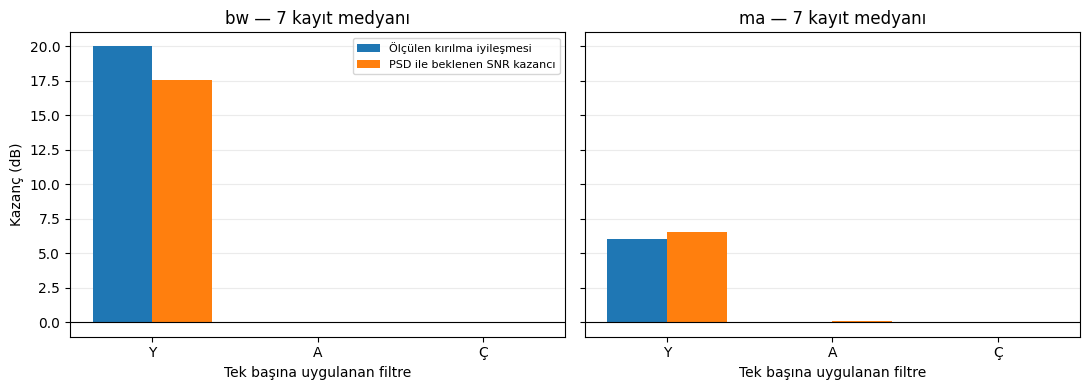

Şekil ve 3 sonuç tablosu 'sonuclar' klasörüne kaydedildi.


In [7]:
import matplotlib.pyplot as plt  # Grafik çizmek için.
from pathlib import Path  # Çıktı klasörü oluşturmak için.

cikti = Path("sonuclar")  # Dosyaların kaydedileceği klasörün adını belirle.
cikti.mkdir(exist_ok=True)  # Klasör yoksa oluştur.

kirilma_tablosu.to_csv(cikti / "kirilma_sonuclari.csv", index=False)  # Kayıt bazında kırılmaları kaydet.
psd_tablosu.to_csv(cikti / "psd_karsilastirma.csv", index=False)  # Ayrıntılı PSD karşılaştırmasını kaydet.
psd_ozet.to_csv(cikti / "medyan_ozet.csv")  # Yedi kayıt medyanlarını kaydet.

fig, eksenler = plt.subplots(1, 2, figsize=(11, 4), sharey=True)  # Tek şekil içinde iki panel oluştur.
filtre_sirasi = ["Y", "A", "Ç"]  # Filtrelerin gösterim sırasını belirle.
konum = np.arange(len(filtre_sirasi))  # Üç filtre için yatay konumları oluştur.

for eksen, ad in zip(eksenler, ["bw", "ma"]):  # Her gürültüye bir panel ayır.
    tablo = psd_ozet.loc[ad].reindex(filtre_sirasi)  # Medyanları istenen sırada al.
    eksen.bar(konum - 0.18, tablo["olculen_fark_dB"], width=0.36,
              label="Ölçülen kırılma iyileşmesi")  # Ölçülen farkları çiz.
    eksen.bar(konum + 0.18, tablo["PSD_ongoru_dB"], width=0.36,
              label="PSD ile beklenen SNR kazancı")  # Güç hesabından gelen öngörüleri çiz.
    eksen.set_xticks(konum, filtre_sirasi)  # Yatay eksene filtre adlarını yaz.
    eksen.set_title(f"{ad} — 7 kayıt medyanı")  # Panelin başlığını yaz.
    eksen.set_xlabel("Tek başına uygulanan filtre")  # Filtrelerin ayrı denendiğini belirt.
    eksen.axhline(0, color="black", linewidth=0.8)  # Sıfır çizgisini göster.
    eksen.grid(axis="y", alpha=0.25)  # Dikey değerleri okumayı kolaylaştır.
    eksen.set_axisbelow(True)  # Izgarayı sütunların arkasına al.

eksenler[0].set_ylabel("Kazanç (dB)")  # Ortak dikey ekseni adlandır.
eksenler[0].legend(fontsize=8)  # İki sütun türünü açıkla.
fig.tight_layout()  # Başlık ve eksenlerin yerleşimini düzenle.
fig.savefig(cikti / "filtre_katkisi.png", dpi=200, bbox_inches="tight")  # Şekli PNG olarak kaydet.
plt.show()  # Şekli ekranda göster.
print("Şekil ve 3 sonuç tablosu 'sonuclar' klasörüne kaydedildi.")  # Kaydı bildir.

In [8]:
from zipfile import ZipFile  # Sonuçları tek bir ZIP dosyasında toplamak için.
from google.colab import files  # Hazırlanan dosyayı bilgisayarına indirmek için.

dosyalar = [  # Yalnız teslim için gerekli dosyaları seç.
    "params.json",  # Deney ve PSD ayarları.
    "sonuclar/kirilma_sonuclari.csv",  # Kayıt bazında kırılma sonuçları.
    "sonuclar/psd_karsilastirma.csv",  # Ayrıntılı ölçüm ve PSD karşılaştırması.
    "sonuclar/medyan_ozet.csv",  # Yedi kaydın medyan sonuçları.
    "sonuclar/filtre_katkisi.png"  # Kontrol ettiğimiz grafik.
]

with ZipFile("eem4011_sonuclar.zip", "w") as paket:  # ZIP dosyasını oluştur.
    for dosya in dosyalar:  # Seçilen dosyaları sırayla işle.
        paket.write(dosya)  # Dosyayı kendi adıyla pakete ekle.

print("Sonuç paketi hazır; indirme başlatılıyor.")  # İşlemin durumunu göster.
files.download("eem4011_sonuclar.zip")  # ZIP dosyasını bilgisayarına indir.

Sonuç paketi hazır; indirme başlatılıyor.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
# Veriler, sabitler ve önceki hesaplama fonksiyonlarının adlarını listele.
gerekli_adlar = [
    "params", "x", "ref", "gurultu",
    "r_tespit", "f1_hesapla", "kirilma"
]

# Listedeki her adı tek tek kontrol et.
for ad in gerekli_adlar:
    # Ad mevcut Colab oturumunda tanımlıysa "VAR", değilse "YOK" yaz.
    print(f"{ad}: {'VAR' if ad in globals() else 'YOK'}")

params: YOK
x: YOK
ref: YOK
gurultu: YOK
r_tespit: YOK
f1_hesapla: YOK
kirilma: YOK


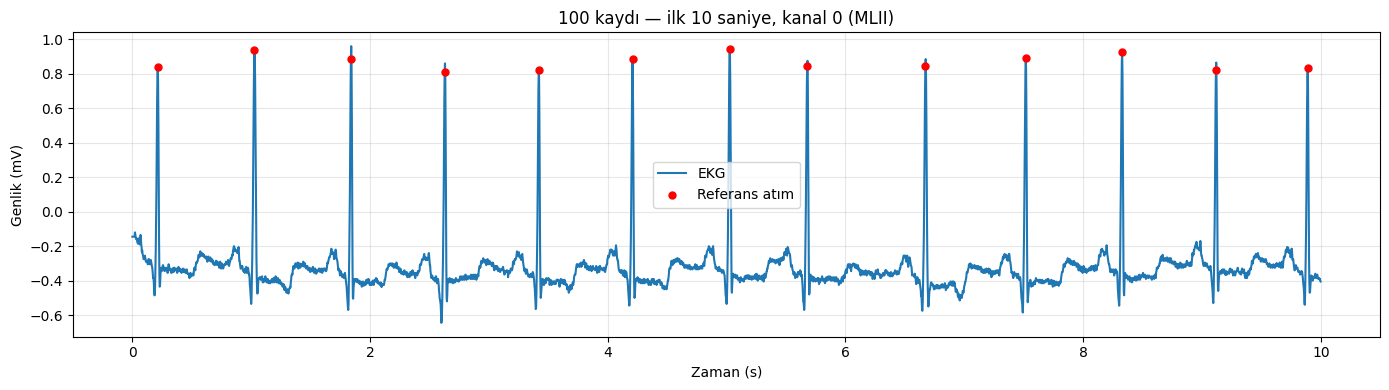

In [ ]:
import matplotlib.pyplot as plt  # Grafik çizmek için.

kayit = "100"  # Görüntülenecek kaydı seç.
fs = params["fs"]  # Önceden belirlediğimiz örnekleme hızını al.
bitis = int(10 * fs)  # İlk 10 saniyenin örnek sayısını hesapla.
zaman = np.arange(bitis) / fs  # Örnek konumlarını saniyeye çevir.
atimlar = ref[kayit][ref[kayit] < bitis]  # Bu aralıktaki referans atımları seç.

plt.figure(figsize=(14, 4))  # Tek bir şekil oluştur.
plt.plot(zaman, x[kayit][:bitis], label="EKG")  # EKG'yi çiz.
plt.scatter(atimlar / fs, x[kayit][atimlar],
            color="red", s=25, label="Referans atım", zorder=3)  # Referansları işaretle.
plt.xlabel("Zaman (s)")  # Yatay ekseni adlandır.
plt.ylabel("Genlik (mV)")  # Dikey ekseni adlandır.
plt.title("100 kaydı — ilk 10 saniye, kanal 0 (MLII)")  # Başlığı ekle.
plt.legend()  # Çizgi ve işaretlerin açıklamasını göster.
plt.grid(alpha=0.3)  # Okumayı kolaylaştıran ızgarayı ekle.
plt.tight_layout()  # Yazıların şekle sığmasını sağla.
plt.show()  # Şekli göster.

In [ ]:
from scipy.signal import find_peaks  # Sinyaldeki tepeleri bulmak için.

def r_tespit(sinyal):  # Sonraki karşılaştırmalarda da aynı tespit yöntemini kullan.
    esik = np.mean(sinyal) + params["k_esik"] * np.std(sinyal)  # Genlik eşiğini hesapla.
    tepeler, _ = find_peaks(sinyal, height=esik, distance=params["distance"])  # Eşiği geçen tepeleri bul.
    return tepeler  # Bulunan tepelerin örnek konumlarını döndür.

def f1_hesapla(tepeler, referans):  # Tespitleri referanslarla bire bir eşleştir.
    i, j, tp = 0, 0, 0  # Tespit sırası, referans sırası ve doğru tespit sayısı.
    tol = params["tolerans"]  # İzin verilen zaman farkını örnek cinsinden al.
    while i < len(tepeler) and j < len(referans):  # İki listede de atım varken devam et.
        fark = int(tepeler[i]) - int(referans[j])  # Tespit ile referansın konum farkını hesapla.
        if fark < -tol:  # Tespit, bu referans için çok erkense:
            i += 1  # Sonraki tespite geç.
        elif fark > tol:  # Referans, bu tespit için çok erkense:
            j += 1  # Sonraki referansa geç.
        else:  # Fark tolerans içindeyse:
            tp += 1  # Bir doğru tespit say.
            i += 1  # Eşleşen tespiti tekrar kullanma.
            j += 1  # Eşleşen referansı tekrar kullanma.
    fp = len(tepeler) - tp  # Eşleşmeyen tespitler: yanlış pozitif.
    fn = len(referans) - tp  # Bulunamayan referanslar: kaçırılan atım.
    payda = 2 * tp + fp + fn  # F1 hesabının paydasını oluştur.
    return 2 * tp / payda if payda > 0 else np.nan  # F1 değerini döndür.

baseline_tepeler = r_tespit(x["100"])  # 100 kaydının tamamında tespit yap.
baseline_f1 = f1_hesapla(baseline_tepeler, ref["100"])  # Referansa göre F1 hesapla.
print(f"100 | ek gürültü yok | filtre yok | baseline F1 = {baseline_f1:.6f}")  # Tek baseline sayısını yazdır.


100 | ek gürültü yok | filtre yok | baseline F1 = 0.999560


In [ ]:
from scipy.signal import butter, sosfiltfilt  # Y filtresini oluşturmak ve uygulamak için.

kayit = "100"  # İlk karşılaştırmanın kaydı.
temiz = x[kayit]  # Bellekteki EKG'yi al; yeniden veri okuma.
bw = gurultu["bw"]  # Bellekteki bw gürültüsünü al.
assert len(bw) >= len(temiz), "Gürültü kaydı EKG'den kısa."  # Uzunluğu kontrol et.
bw = bw[:len(temiz)].copy()  # EKG ile aynı uzunluktaki başlangıç kesitini kullan.
bw = bw - np.mean(bw)  # Gürültünün ortalamasını sıfırla.
ekg_gucu = np.var(temiz)  # EKG gücünü ortalamadan arındırılmış güç olarak tanımla.
gurultu_gucu = np.var(bw)  # Gürültünün gücünü aynı tanımla hesapla.
assert ekg_gucu > 0 and gurultu_gucu > 0, "Sinyal güçleri pozitif olmalı."  # Ölçeklemeyi kontrol et.

sos_y = butter(
    params["Y"]["derece"],  # Sabitlerdeki 2. dereceyi kullan.
    params["Y"]["frekans_hz"],  # Sabitlerdeki 0,5 Hz kesimini kullan.
    btype="highpass",  # Yüksek geçiren filtre seç.
    fs=params["fs"],  # Örnekleme hızını sabitlerden al.
    output="sos"  # Filtreyi sayısal açıdan uygun bölüm biçiminde oluştur.
)

sonuc_100_bw = []  # Sonraki hücrelerde kullanmak üzere sonuçları sakla.

for snr in params["SNR"]:  # Belirlenen SNR listesini yüksekten düşüğe tara.
    katsayi = np.sqrt(ekg_gucu / (gurultu_gucu * 10 ** (snr / 10)))  # Hedef SNR için gürültüyü ölçekle.
    ham = temiz + katsayi * bw  # Gürültülü, filtresiz EKG'yi oluştur.
    y = sosfiltfilt(sos_y, ham)  # Aynı EKG'ye Y filtresini ileri–geri uygula.
    f1_ham = f1_hesapla(r_tespit(ham), ref[kayit])  # Filtresiz F1'i hesapla.
    f1_y = f1_hesapla(r_tespit(y), ref[kayit])  # Y sonrasındaki F1'i hesapla.
    sonuc_100_bw.append({"SNR": snr, "ham": f1_ham, "Y": f1_y})  # Sonuçları bellekte tut.

def kirilma(sonuclar, yontem):  # İlk eşik altı sonucu bul.
    for sira, satir in enumerate(sonuclar):  # SNR sırasıyla sonuçları incele.
        if satir[yontem] < params["f1_esik"]:  # F1 eşik altına düştüyse:
            if sira == 0:  # En yüksek SNR'de bile eşik sağlanmadıysa:
                return ">+30"  # Kırılmayı tarama dışında etiketle.
            return satir["SNR"]  # İlk başarısız SNR'yi döndür.
    return "<-30"  # Hiç eşik altına düşmediyse tarama dışında etiketle.

print("SNR (dB) | Ham F1   | Y F1")  # Tablo başlığını yaz.
for satir in sonuc_100_bw:  # Hesaplanan sonuçları sırayla göster.
    print(f'{satir["SNR"]:+8d} | {satir["ham"]:.6f} | {satir["Y"]:.6f}')

print("Ham kırılma (dB):", kirilma(sonuc_100_bw, "ham"))  # Ham kırılmayı göster.
print("Y kırılma (dB):", kirilma(sonuc_100_bw, "Y"))  # Y kırılmasını göster.

SNR (dB) | Ham F1   | Y F1
     +30 | 0.999560 | 0.999560
     +28 | 0.999560 | 0.999560
     +26 | 0.999560 | 0.999560
     +24 | 0.999560 | 0.999560
     +22 | 0.999560 | 0.999560
     +20 | 0.999560 | 0.999560
     +18 | 0.999560 | 0.999560
     +16 | 0.999560 | 0.999560
     +14 | 0.999560 | 0.999560
     +12 | 0.999560 | 0.999560
     +10 | 0.999120 | 0.999560
      +8 | 0.998901 | 0.999560
      +6 | 0.998681 | 0.999560
      +4 | 0.998461 | 0.999560
      +2 | 0.995814 | 0.999560
      +0 | 0.986034 | 0.999560
      -2 | 0.957670 | 0.999560
      -4 | 0.870507 | 0.999120
      -6 | 0.668792 | 0.998681
      -8 | 0.370265 | 0.998242
     -10 | 0.170635 | 0.997802
     -12 | 0.082124 | 0.997364
     -14 | 0.052211 | 0.996047
     -16 | 0.039831 | 0.993862
     -18 | 0.034820 | 0.990581
     -20 | 0.032313 | 0.980583
     -22 | 0.027280 | 0.937300
     -24 | 0.027269 | 0.770811
     -26 | 0.027246 | 0.444150
     -28 | 0.027234 | 0.212766
     -30 | 0.026361 | 0.121961
Ham kırılma 